# Seeded Weekly Comparison (DQN vs DQN No-LLM)

This notebook summarizes 5 seeded weekly training runs with 10% stop-loss at inference.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

summary_path = 'test_results/seeded_weekly_full/seeded_weekly_summary.csv'
raw_path = 'test_results/seeded_weekly_full/seeded_weekly_runs.csv'
summary = pd.read_csv(summary_path)
raw = pd.read_csv(raw_path)
summary.head()


,ticker,method,runs,return_mean_pct,return_std_pct,final_mean,final_std,sharpe_mean,sharpe_std,win_rate_mean,win_rate_std,max_drawdown_mean,max_drawdown_std
0,AAPL,dqn,5,26.728261,25.057232,12672.826118,2505.723208,1.147896,0.895864,33.636364,8.743356,26.532914,3.711811
1,AAPL,dqn_nollm,5,31.672940,14.693824,13167.293980,1469.382415,1.475800,0.388999,37.454545,19.019346,25.418021,11.680919
2,AMZN,dqn,5,43.429772,27.117980,14342.977162,2711.797989,1.900957,1.022721,30.727273,9.736190,21.139599,9.503831
3,AMZN,dqn_nollm,5,30.786873,17.630998,13078.687264,1763.099849,1.234149,0.693611,35.272727,19.869408,20.714934,11.776644
4,ASML,dqn,5,39.213749,12.858345,13921.374942,1285.834508,1.453887,0.283147,34.181818,7.030042,27.620739,8.104727


In [2]:
def fmt(mean, std):
    return f"{mean:.2f} ± {std:.2f}"

ret = summary.pivot(index='ticker', columns='method', values=['return_mean_pct', 'return_std_pct'])
fin = summary.pivot(index='ticker', columns='method', values=['final_mean', 'final_std'])

rows = []
for ticker in sorted(summary['ticker'].unique()):
    row = {
        'Ticker': ticker,
        'DQN Return % (mean±std)': fmt(ret.loc[ticker, ('return_mean_pct', 'dqn')], ret.loc[ticker, ('return_std_pct', 'dqn')]),
        'DQN No-LLM Return % (mean±std)': fmt(ret.loc[ticker, ('return_mean_pct', 'dqn_nollm')], ret.loc[ticker, ('return_std_pct', 'dqn_nollm')]),
        'DQN Final $ (mean±std)': fmt(fin.loc[ticker, ('final_mean', 'dqn')], fin.loc[ticker, ('final_std', 'dqn')]),
        'DQN No-LLM Final $ (mean±std)': fmt(fin.loc[ticker, ('final_mean', 'dqn_nollm')], fin.loc[ticker, ('final_std', 'dqn_nollm')]),
    }
    rows.append(row)
display(pd.DataFrame(rows))


,Ticker,DQN Return % (mean±std),DQN No-LLM Return % (mean±std),DQN Final $ (mean±std),DQN No-LLM Final $ (mean±std)
0,AAPL,26.73 ± 25.06,31.67 ± 14.69,12672.83 ± 2505.72,13167.29 ± 1469.38
1,AMZN,43.43 ± 27.12,30.79 ± 17.63,14342.98 ± 2711.80,13078.69 ± 1763.10
2,ASML,39.21 ± 12.86,44.45 ± 36.17,13921.37 ± 1285.83,14444.65 ± 3617.09
3,GOOGL,51.20 ± 38.21,98.59 ± 55.86,15119.76 ± 3820.56,19858.93 ± 5585.55
4,META,45.06 ± 18.61,14.13 ± 26.10,14505.90 ± 1860.97,11413.45 ± 2609.52
5,MSFT,-5.99 ± 9.59,-3.17 ± 2.60,9400.73 ± 958.70,9683.06 ± 260.40
6,NVDA,111.01 ± 62.18,90.76 ± 68.78,21101.02 ± 6217.79,19076.07 ± 6877.73
7,TSLA,66.76 ± 63.43,32.11 ± 48.93,16675.97 ± 6342.58,13211.20 ± 4892.91
8,TSM,52.37 ± 24.32,94.63 ± 66.39,15237.46 ± 2431.55,19463.45 ± 6638.70


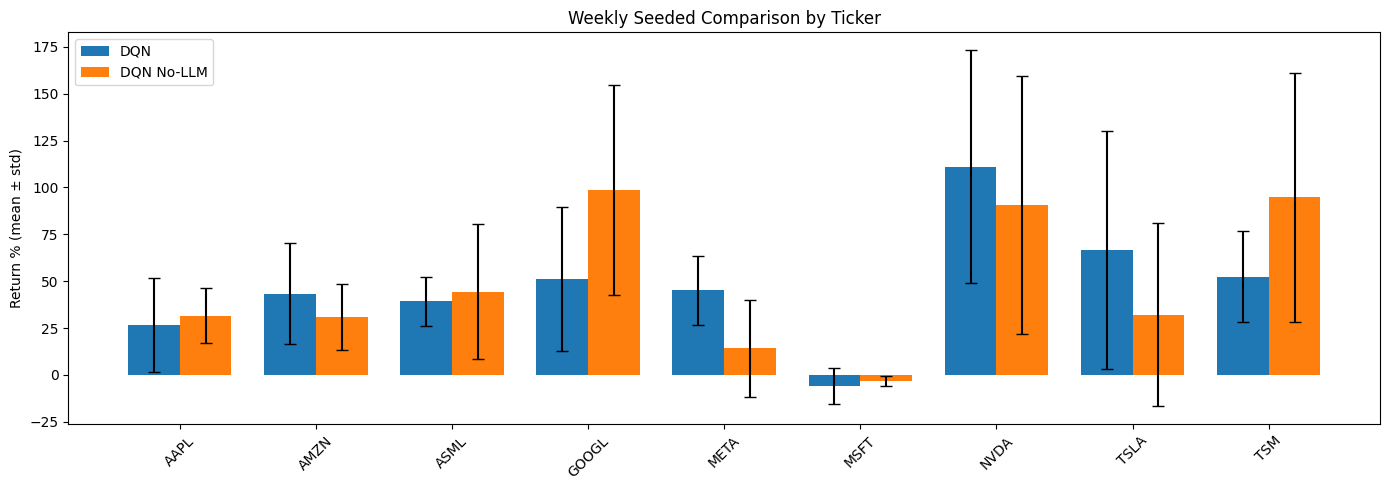

In [3]:
tickers = sorted(summary['ticker'].unique())
x = np.arange(len(tickers))
width = 0.38

dqn = summary[summary['method']=='dqn'].set_index('ticker').loc[tickers]
nollm = summary[summary['method']=='dqn_nollm'].set_index('ticker').loc[tickers]

plt.figure(figsize=(14, 5))
plt.bar(x - width/2, dqn['return_mean_pct'], width, yerr=dqn['return_std_pct'], capsize=4, label='DQN')
plt.bar(x + width/2, nollm['return_mean_pct'], width, yerr=nollm['return_std_pct'], capsize=4, label='DQN No-LLM')
plt.xticks(x, tickers, rotation=45)
plt.ylabel('Return % (mean ± std)')
plt.title('Weekly Seeded Comparison by Ticker')
plt.legend()
plt.tight_layout()
plt.show()
